In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully!


In [18]:
import os
os.makedirs("outputs", exist_ok=True)
print("Outputs folder created successfully!")

Outputs folder created successfully!


In [19]:
df = pd.read_csv("DatasetC .csv")

print(df.head())

   Restaurant ID         Restaurant Name  Country Code              City  \
0        6317637        Le Petit Souffle           162       Makati City   
1        6304287        Izakaya Kikufuji           162       Makati City   
2        6300002  Heat - Edsa Shangri-La           162  Mandaluyong City   
3        6318506                    Ooma           162  Mandaluyong City   
4        6314302             Sambo Kojin           162  Mandaluyong City   

                                             Address  \
0  Third Floor, Century City Mall, Kalayaan Avenu...   
1  Little Tokyo, 2277 Chino Roces Avenue, Legaspi...   
2  Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...   
3  Third Floor, Mega Fashion Hall, SM Megamall, O...   
4  Third Floor, Mega Atrium, SM Megamall, Ortigas...   

                                     Locality  \
0   Century City Mall, Poblacion, Makati City   
1  Little Tokyo, Legaspi Village, Makati City   
2  Edsa Shangri-La, Ortigas, Mandaluyong City   
3      SM 

In [20]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 9551
Number of columns: 21


In [21]:
print(df.columns.tolist())

['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address', 'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines', 'Average Cost for two', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu', 'Price range', 'Aggregate rating', 'Rating color', 'Rating text', 'Votes']


In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   str    
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   str    
 4   Address               9551 non-null   str    
 5   Locality              9551 non-null   str    
 6   Locality Verbose      9551 non-null   str    
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   str    
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   str    
 12  Has Table booking     9551 non-null   str    
 13  Has Online delivery   9551 non-null   str    
 14  Is delivering now     9551 non-null   str    
 15  Switch to order menu  9551 non-n

In [23]:
print(df.isnull().sum())

Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                9
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64


In [24]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [25]:
print(df.describe())

       Restaurant ID  Country Code    Longitude     Latitude  \
count   9.551000e+03   9551.000000  9551.000000  9551.000000   
mean    9.051128e+06     18.365616    64.126574    25.854381   
std     8.791521e+06     56.750546    41.467058    11.007935   
min     5.300000e+01      1.000000  -157.948486   -41.330428   
25%     3.019625e+05      1.000000    77.081343    28.478713   
50%     6.004089e+06      1.000000    77.191964    28.570469   
75%     1.835229e+07      1.000000    77.282006    28.642758   
max     1.850065e+07    216.000000   174.832089    55.976980   

       Average Cost for two  Price range  Aggregate rating         Votes  
count           9551.000000  9551.000000       9551.000000   9551.000000  
mean            1199.210763     1.804837          2.666370    156.909748  
std            16121.183073     0.905609          1.516378    430.169145  
min                0.000000     1.000000          0.000000      0.000000  
25%              250.000000     1.000000        

In [26]:
print("Number of cities:", df["City"].nunique())

print("Number of cuisines:", df["Cuisines"].nunique())

print("Price ranges:", sorted(df["Price range"].dropna().unique()))

Number of cities: 141
Number of cuisines: 1825
Price ranges: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


In [27]:
# level 1 - task 1 : Top Cuisines 
# Remove rows where cuisine information is missing
cuisine_data = df["Cuisines"].dropna()
# Split multiple cuisines and count each cuisine
cuisine_counts = (
    cuisine_data
    .str.split(",")
    .explode()
    .str.strip()
    .value_counts()
)
# Select the top three cuisines
top_three = cuisine_counts.head(3)
# Calculate the percentage of restaurants
# that serve each cuisine
cuisine_percentage = (top_three / len(df)) * 100
# Combine the results
top_cuisines = pd.DataFrame({
    "Restaurant Count": top_three,
    "Percentage": cuisine_percentage
})
print(top_cuisines)

              Restaurant Count  Percentage
Cuisines                                  
North Indian              3960   41.461627
Chinese                   2735   28.635745
Fast Food                 1986   20.793634


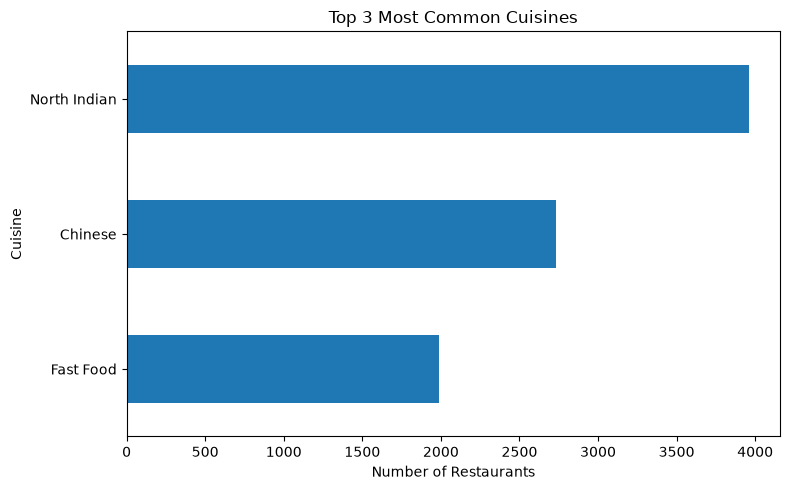

In [28]:
# Create a bar chart 
plt.figure(figsize=(8, 5))
top_three.sort_values().plot(
    kind="barh"
)
plt.title("Top 3 Most Common Cuisines")
plt.xlabel("Number of Restaurants")
plt.ylabel("Cuisine")
plt.tight_layout()
plt.savefig("outputs/top_cuisines.png", dpi=300)
plt.show()

In [29]:
# level 1 - Task 2: City Analysis
city_counts = df["City"].value_counts()
print("Top 10 Cities by Restaurant Count")
print(city_counts.head(10))

Top 10 Cities by Restaurant Count
City
New Delhi       5473
Gurgaon         1118
Noida           1080
Faridabad        251
Ghaziabad         25
Ahmedabad         21
Amritsar          21
Bhubaneshwar      21
Guwahati          21
Lucknow           21
Name: count, dtype: int64


In [30]:
# caluculate the average rating for each city
city_ratings = (
    df.groupby("City")["Aggregate rating"]
    .mean()
    .sort_values(ascending=False)
)
print(city_ratings.head(10))

City
Inner City          4.900000
Quezon City         4.800000
Makati City         4.650000
Pasig City          4.633333
Mandaluyong City    4.625000
Beechworth          4.600000
London              4.535000
Taguig City         4.525000
Secunderabad        4.500000
Lincoln             4.500000
Name: Aggregate rating, dtype: float64


In [31]:
#find the city with the highest average rating
city_rating_summary = (
    df.groupby("City")
    .agg(
        Restaurant_Count=("Restaurant ID", "count"),
        Average_Rating=("Aggregate rating", "mean")
    )
)
# Consider cities with at least 5 restaurant records
eligible_cities = city_rating_summary[
    city_rating_summary["Restaurant_Count"] >= 5
]
highest_rated_city = eligible_cities[
    "Average_Rating"
].idxmax()
print("City with the highest average rating:", highest_rated_city)
print(
    "Average rating:",
    eligible_cities.loc[highest_rated_city, "Average_Rating"]
)

City with the highest average rating: London
Average rating: 4.535


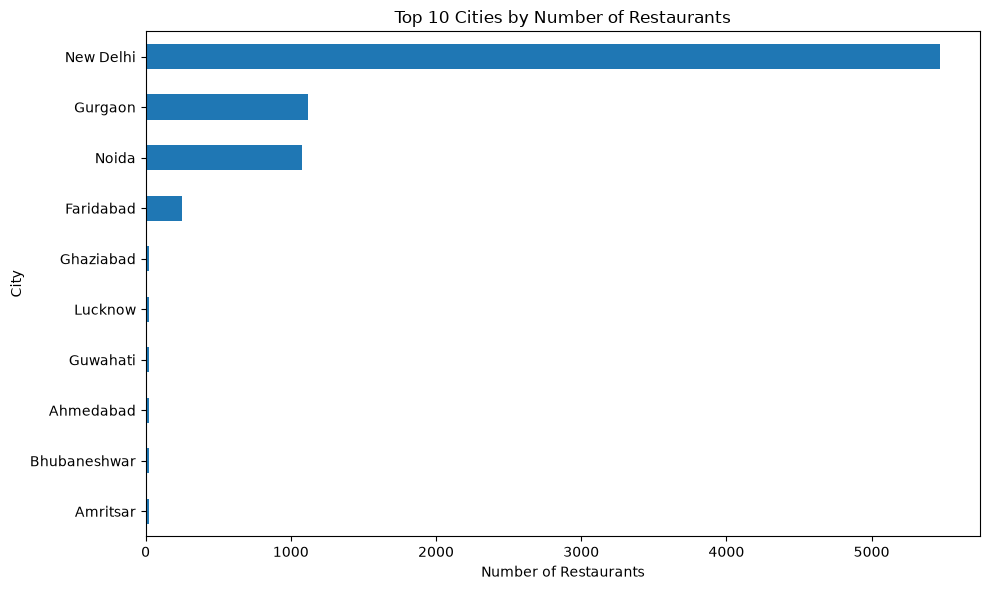

In [32]:
#create a chart
plt.figure(figsize=(10, 6))
city_counts.head(10).sort_values().plot(
    kind="barh"
)
plt.title("Top 10 Cities by Number of Restaurants")
plt.xlabel("Number of Restaurants")
plt.ylabel("City")
plt.tight_layout()
plt.savefig("outputs/city_analysis.png", dpi=300)
plt.show()

In [33]:
#level 1-Task 3: price range distribution
#Count the restaurants in each price range
price_counts = df["Price range"].value_counts().sort_index()
print(price_counts)

Price range
1    4444
2    3113
3    1408
4     586
Name: count, dtype: int64


In [35]:
#Calculate the percentage
price_percentage = (
    df["Price range"].value_counts(normalize=True).sort_index() * 100
)
price_summary = pd.DataFrame({
    "Restaurant Count": price_counts,
    "Percentage": price_percentage
})
print(price_summary)

             Restaurant Count  Percentage
Price range                              
1                        4444   46.529159
2                        3113   32.593446
3                        1408   14.741912
4                         586    6.135483


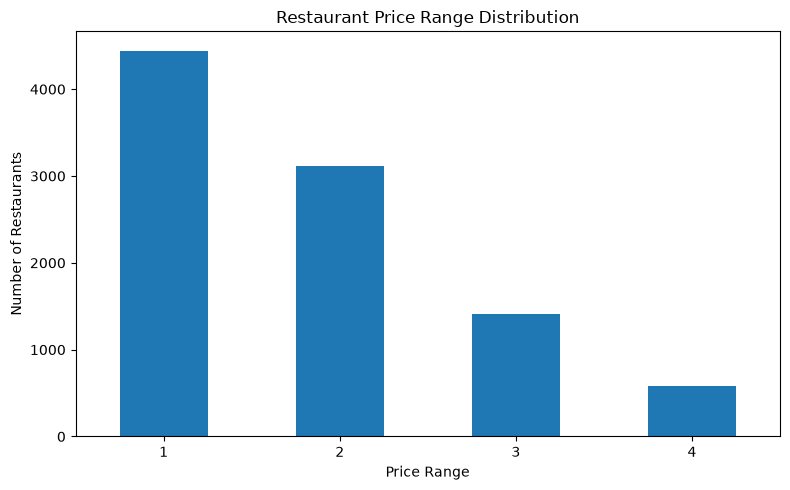

In [36]:
# create a bar chart
plt.figure(figsize=(8, 5))
price_counts.plot(
    kind="bar"
)
plt.title("Restaurant Price Range Distribution")
plt.xlabel("Price Range")
plt.ylabel("Number of Restaurants")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("outputs/price_distribution.png", dpi=300)
plt.show()

In [37]:
#level 1 - Task 4 : Online Delivery
#Count restaurants offering delivery
delivery_counts = df["Has Online delivery"].value_counts()
print(delivery_counts)

Has Online delivery
No     7100
Yes    2451
Name: count, dtype: int64


In [38]:
#Calculate the delivery percentage
delivery_percentage = (
    df["Has Online delivery"]
    .value_counts(normalize=True) * 100
)
print("Online Delivery Percentage:")
print(delivery_percentage)

Online Delivery Percentage:
Has Online delivery
No     74.337766
Yes    25.662234
Name: proportion, dtype: float64


In [39]:
#Compare average ratings
delivery_ratings = (
    df.groupby("Has Online delivery")["Aggregate rating"]
    .mean()
)
print("Average Ratings by Online Delivery Availability:")
print(delivery_ratings)

Average Ratings by Online Delivery Availability:
Has Online delivery
No     2.465296
Yes    3.248837
Name: Aggregate rating, dtype: float64


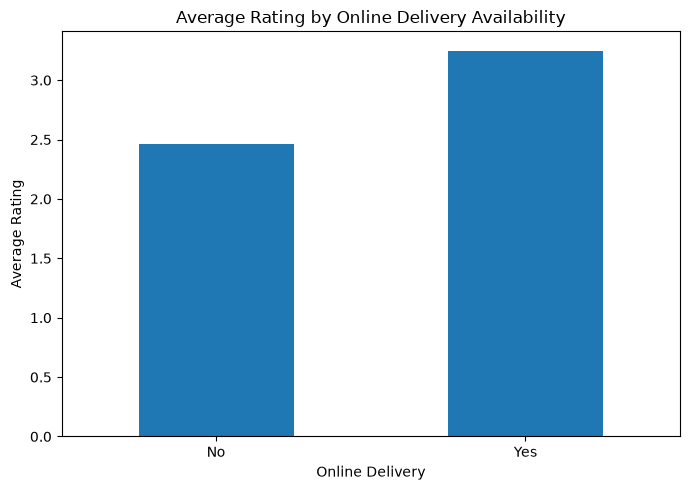

In [40]:
#Create  a chart
plt.figure(figsize=(7, 5))
delivery_ratings.plot(
    kind="bar"
)
plt.title("Average Rating by Online Delivery Availability")
plt.xlabel("Online Delivery")
plt.ylabel("Average Rating")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("outputs/online_delivery.png", dpi=300)
plt.show()

In [41]:
# level 2 - Task 1: Restaurant Ratings
# Understand the rating column
print(df["Aggregate rating"].describe())

count    9551.000000
mean        2.666370
std         1.516378
min         0.000000
25%         2.500000
50%         3.200000
75%         3.700000
max         4.900000
Name: Aggregate rating, dtype: float64


In [42]:
# Create rating categories
rating_data = df["Aggregate rating"].dropna()
rating_bins = np.arange(0, 5.5, 0.5)
rating_labels = [
    f"{rating_bins[i]:.1f}-{rating_bins[i+1]:.1f}"
    for i in range(len(rating_bins) - 1)
]
rating_categories = pd.cut(
    rating_data,
    bins=rating_bins,
    labels=rating_labels,
    include_lowest=True
)
rating_counts = rating_categories.value_counts().sort_index()
print("Rating Distribution:")
print(rating_counts)

Rating Distribution:
Aggregate rating
0.0-0.5    2148
0.5-1.0       0
1.0-1.5       0
1.5-2.0      10
2.0-2.5     286
2.5-3.0    1605
3.0-3.5    2502
3.5-4.0    1886
4.0-4.5     908
4.5-5.0     206
Name: count, dtype: int64


In [43]:
# Calculate the average number of votes
average_votes = df["Votes"].mean()
print("Average Votes per Restaurant:", average_votes)

Average Votes per Restaurant: 156.909747670401


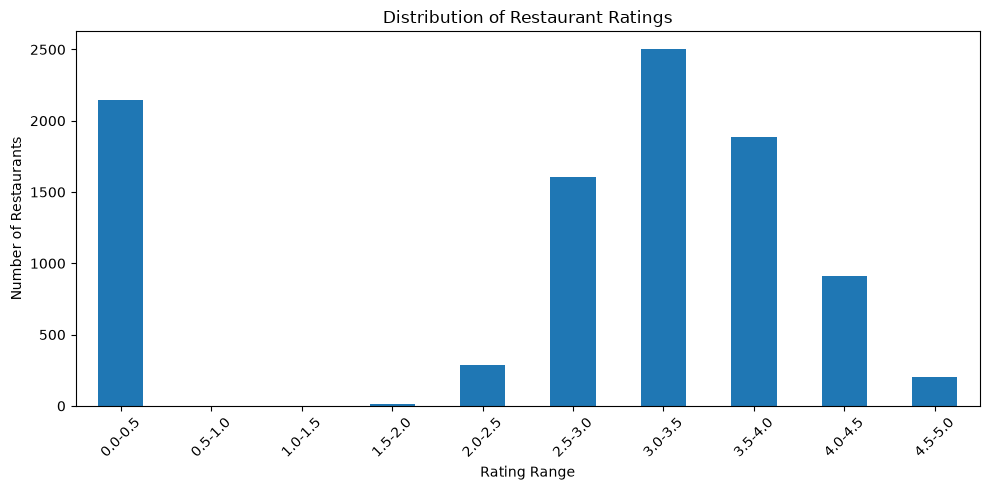

In [44]:
# Visualize rating distribution
plt.figure(figsize=(10, 5))
rating_counts.plot(
    kind="bar"
)
plt.title("Distribution of Restaurant Ratings")
plt.xlabel("Rating Range")
plt.ylabel("Number of Restaurants")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("outputs/ratings_distribution.png", dpi=300)
plt.show()

In [45]:
#level 2 - Task 2: Cuisine combination
#Count cuisine combinations
cuisine_combinations = (
    df["Cuisines"]
    .dropna()
    .str.split(",")
    .apply(lambda cuisines: ", ".join(
        sorted(c.strip() for c in cuisines)
    ))
)
combination_counts = cuisine_combinations.value_counts()
print("Top 10 Cuisine Combinations:")
print(combination_counts.head(10))

Top 10 Cuisine Combinations:
Cuisines
North Indian                      936
Chinese, North Indian             616
Mughlai, North Indian             394
Chinese                           354
Fast Food                         354
Chinese, Mughlai, North Indian    306
Cafe                              299
Bakery                            218
Bakery, Desserts                  181
Chinese, Fast Food                159
Name: count, dtype: int64


In [46]:
# Compare average ratings by cuisine combination
df["Cuisine Combination"] = (
    df["Cuisines"]
    .fillna("")
    .apply(lambda value: ", ".join(
        sorted(c.strip() for c in value.split(",") if c.strip())
    ))
)
combination_ratings = (
    df[df["Cuisine Combination"] != ""]
    .groupby("Cuisine Combination")
    .agg(
        Restaurant_Count=("Restaurant ID", "count"),
        Average_Rating=("Aggregate rating", "mean")
    )
)
# Require at least 5 restaurant records per combination
popular_combinations = combination_ratings[
    combination_ratings["Restaurant_Count"] >= 5
]
print(
    popular_combinations
    .sort_values("Restaurant_Count", ascending=False)
    .head(10)
)

                                Restaurant_Count  Average_Rating
Cuisine Combination                                             
North Indian                                 936        1.672329
Chinese, North Indian                        616        2.333442
Mughlai, North Indian                        394        2.767259
Chinese                                      354        2.042090
Fast Food                                    354        2.118362
Chinese, Mughlai, North Indian               306        2.619935
Cafe                                         299        2.890970
Bakery                                       218        1.924312
Bakery, Desserts                             181        2.375691
Chinese, Fast Food                           159        2.069811


In [47]:
# identify highly rated combinations
print(
    popular_combinations
    .sort_values("Average_Rating", ascending=False)
    .head(10)
)

                                       Restaurant_Count  Average_Rating
Cuisine Combination                                                    
European, Mediterranean, North Indian                 8        4.587500
Burger                                                6        4.450000
Modern Indian                                        11        4.345455
Indian                                               18        4.250000
International                                         6        4.233333
Italian, Pizza, Sandwich                              5        4.220000
French                                                7        4.185714
Steak                                                 7        4.185714
Pizza, Sandwich                                       5        4.140000
Seafood                                              14        4.114286


In [49]:
#Level 2 — Task 3: Geographic Analysis
#Prepare the geographic data
geo_df = df.dropna(
    subset=["Longitude", "Latitude"]
).copy()
print(geo_df[["Longitude", "Latitude"]].head())

    Longitude   Latitude
0  121.027535  14.565443
1  121.014101  14.553708
2  121.056831  14.581404
3  121.056475  14.585318
4  121.057508  14.584450


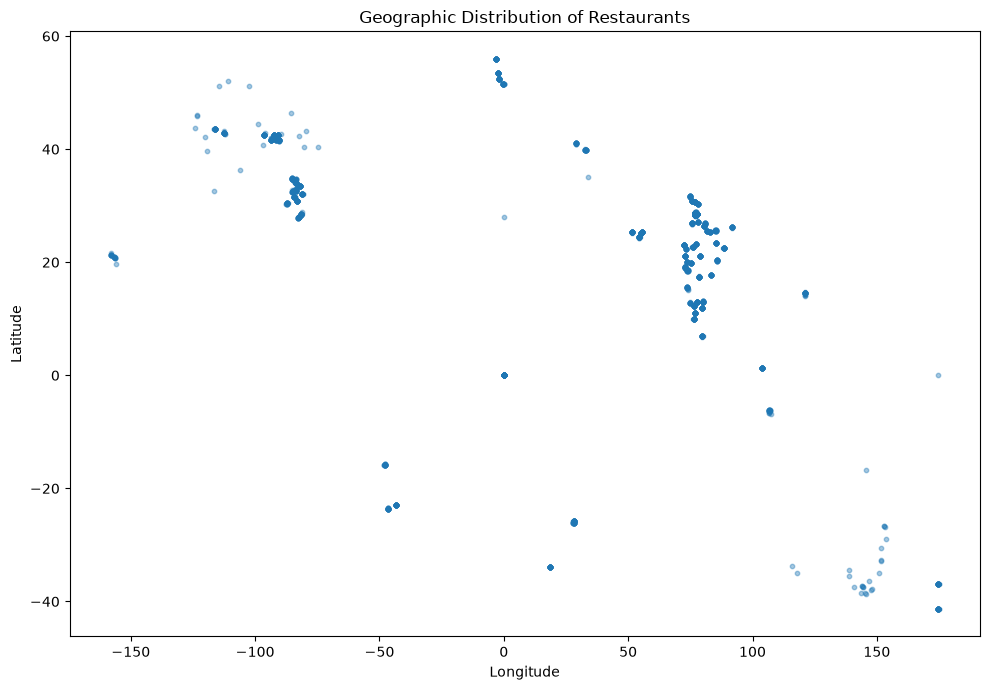

In [50]:
# Create the restaurant location map
plt.figure(figsize=(10, 7))
plt.scatter(
    geo_df["Longitude"],
    geo_df["Latitude"],
    alpha=0.4,
    s=10
)
plt.title("Geographic Distribution of Restaurants")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.savefig("outputs/restaurant_locations.png", dpi=300)
plt.show()

In [51]:
#Level 2 — Task 4: Restaurant Chains
#Count restaurants by name
restaurant_counts = (
    df.groupby("Restaurant Name")
    .agg(
        Outlet_Count=("Restaurant ID", "nunique"),
        Average_Rating=("Aggregate rating", "mean"),
        Total_Votes=("Votes", "sum")
    )
)
print(
    restaurant_counts
    .sort_values("Outlet_Count", ascending=False)
    .head(10)
)

                  Outlet_Count  Average_Rating  Total_Votes
Restaurant Name                                            
Cafe Coffee Day             83        2.419277         2428
Domino's Pizza              79        2.740506         6643
Subway                      63        2.907937         6124
Green Chick Chop            51        2.672549          964
McDonald's                  48        3.339583         5291
Keventers                   34        2.870588         1263
Pizza Hut                   30        3.320000         4961
Giani                       29        2.689655          854
Baskin Robbins              28        1.860714          428
Barbeque Nation             26        4.353846        28142


In [52]:
#Identify possible restaurant chains
restaurant_chains = restaurant_counts[
    restaurant_counts["Outlet_Count"] > 1
].copy()
print("Possible Restaurant Chains:")
print(
    restaurant_chains
    .sort_values("Outlet_Count", ascending=False)
    .head(10)
)

Possible Restaurant Chains:
                  Outlet_Count  Average_Rating  Total_Votes
Restaurant Name                                            
Cafe Coffee Day             83        2.419277         2428
Domino's Pizza              79        2.740506         6643
Subway                      63        2.907937         6124
Green Chick Chop            51        2.672549          964
McDonald's                  48        3.339583         5291
Keventers                   34        2.870588         1263
Pizza Hut                   30        3.320000         4961
Giani                       29        2.689655          854
Baskin Robbins              28        1.860714          428
Barbeque Nation             26        4.353846        28142


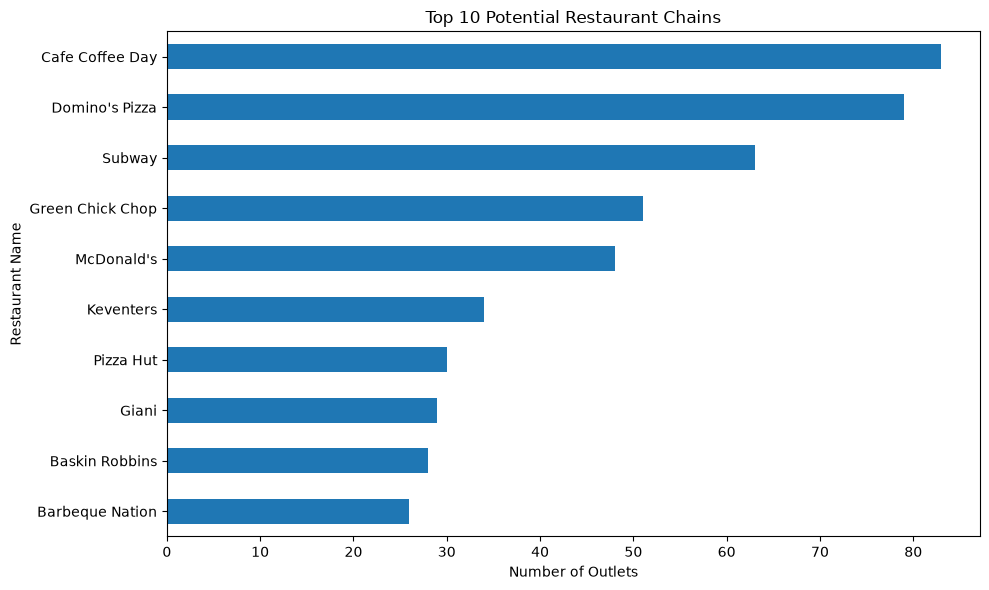

In [53]:
#Visualize the largest potential chains
top_chains = (
    restaurant_chains
    .sort_values("Outlet_Count", ascending=False)
    .head(10)
)
plt.figure(figsize=(10, 6))
top_chains["Outlet_Count"].sort_values().plot(
    kind="barh"
)
plt.title("Top 10 Potential Restaurant Chains")
plt.xlabel("Number of Outlets")
plt.ylabel("Restaurant Name")
plt.tight_layout()
plt.savefig("outputs/restaurant_chains.png", dpi=300)
plt.show()